# линейная регрессия одной переменной

Задача: по числу автомобилей в городе (в тысячах) предсказать месячную прибыль автосервиса (СТО). Функция стоимости и градиентный спуск реализованы тремя независимыми способами (циклом, поэлементно через numpy и полностью в матрично-векторной форме) — они лежат в `linear_regression.py` и сверяются друг с другом ниже как способ самопроверки.

## Импорты и загрузка данных

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from linear_regression import (
    computeCost1, computeCost2, computeCost3,
    gradientDescent1, gradientDescent2, gradientDescent3,
    predict, plot_data, plot_model, plot_theta, trainTest,
)

data = pd.read_csv('data.txt', header=None)
data = data.rename(columns={0: 'x', 1: 'y'})

## Разведочный анализ данных

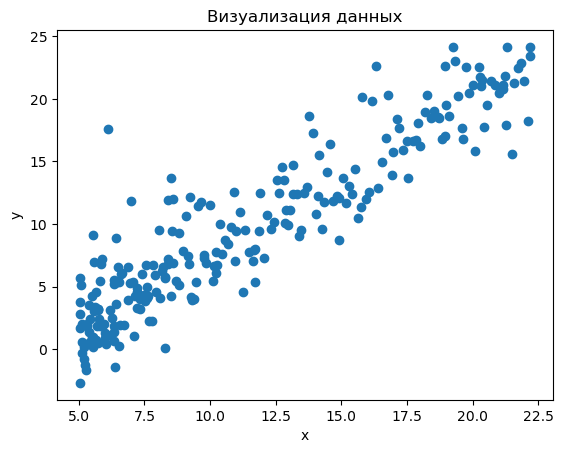

In [5]:
plot_data(data['x'], data['y'])

## Разбиение на обучающую и тестовую выборки

In [7]:
train, test = trainTest(data)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

print(len(train), len(test), sep='\n')

172
75


## Обучение моделей (три реализации)

In [ ]:
theta1 = gradientDescent1(train['x'], train['y'], [0, 0], alpha=0.001)
theta2 = gradientDescent2(train['x'], train['y'], [0, 0], alpha=0.001)
theta3 = gradientDescent3(train['x'], train['y'], [0, 0], alpha=0.001)

cost_history1 = []
cost_history2 = []
cost_history3 = []

for i in range(20000):
    theta1 = gradientDescent1(train['x'], train['y'], theta1, alpha=0.001)
    theta2 = gradientDescent2(train['x'], train['y'], theta2, alpha=0.001)
    theta3 = gradientDescent3(train['x'], train['y'], theta3, alpha=0.001)
    cost_history1.append(computeCost3(train['x'], train['y'], theta1))
    cost_history2.append(computeCost3(train['x'], train['y'], theta2))
    cost_history3.append(computeCost3(train['x'], train['y'], theta3))

print(f"theta1 = [{theta1[0]:.4f}, {theta1[1]:.4f}]")
print(f"theta2 = [{theta2[0]:.4f}, {theta2[1]:.4f}]")
print(f"theta3 = [{theta3[0]:.4f}, {theta3[1]:.4f}]")

## независимая проверка - со sklearn

In [ ]:
model = LinearRegression()
model.fit(train['x'].values.reshape(-1, 1), train['y'])
print(f"theta = [{model.intercept_:.4f}, {model.coef_[0]:.4f}]")


## Проверка согласованности трёх реализаций

Сравниваем J(θ) на train для всех трёх обученных theta — значения должны совпадать с точностью до вычислительной погрешности.


In [ ]:
print(computeCost1(train['x'], train['y'], theta1))
print(computeCost1(train['x'], train['y'], theta2))
print(computeCost1(train['x'], train['y'], theta3))

## Визуализация обученной модели

In [ ]:
theta = theta1

plot_model(train['x'], train['y'], theta)
plot_model(test['x'], test['y'], theta)

## Оценка качества модели

In [ ]:
print(f"J(\u03b8) на обучающей выборке: {predict(train['x'], train['y'], theta)}")
print(f"J(\u03b8) на тестовой выборке: {predict(test['x'], test['y'], theta)}")

## Сходимость градиентного спуска

In [ ]:
plot_theta(cost_history1, cost_history2, cost_history3)

## Сохранение результата

In [ ]:
np.savetxt('Theta.txt', theta)

## Выводы

Все три реализации (цикл, поэлементно, векторно) сошлись к одинаковым весам θ = [-4.2395, 1.2135]. Независимая проверка через sklearn.linear_model.LinearRegression дала практически те же значения (θ = [-4.2428, 1.2137], разница в третьем-четвёртом знаке) — это подтверждает корректность реализации.

J(θ) составил 2.75 на train и 5.33 на test. Разница ожидаема - тестовая выборка меньше, а данные и так довольно сильно разбросаны относительно прямой, так что часть ошибки — естественный шум